In [1]:
import duckdb
import pandas as pd

con = duckdb.connect()

df = con.sql("""
    SELECT *
    FROM read_csv_auto('../data/accepted_2007_to_2018Q4.csv')
    LIMIT 1000
""").df()

df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,None,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,None,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,None,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,None,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,None,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
con.sql("""
    SELECT purpose,
           COUNT(*) AS loans,
           ROUND(AVG(CASE WHEN loan_status = 'Charged Off' THEN 1 ELSE 0 END), 3) AS default_rate
    FROM read_csv_auto('../data/accepted_2007_to_2018Q4.csv')
    WHERE loan_status = 'Fully Paid' OR loan_status = 'Charged Off'
    GROUP BY purpose
    ORDER BY default_rate DESC
""").df()

,purpose,loans,default_rate
0,small_business,15416,0.297
1,renewable_energy,933,0.237
2,moving,9480,0.234
3,house,7253,0.219
4,medical,15554,0.218
5,debt_consolidation,780321,0.211
6,other,77875,0.210
7,vacation,9065,0.192
8,major_purchase,29425,0.186
9,home_improvement,87504,0.177


In [3]:
import os

print("Current working directory:", os.getcwd())

Current working directory: c:\Users\MASTER\credit-risk-project\notebooks


In [4]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

con = duckdb.connect("../data/lending.duckdb")

In [5]:
file_path = "../data/lending.duckdb"

if os.path.exists(file_path):
    print("Yes, the file exists.")
else:
    print("No, the file does not exist.")

Yes, the file exists.


In [8]:
con.sql("""
CREATE OR REPLACE TABLE loans AS
SELECT
    loan_amnt, term, int_rate, installment, grade, sub_grade, emp_length,
    home_ownership, annual_inc, verification_status, issue_d, loan_status,
    purpose, addr_state, dti, delinq_2yrs, earliest_cr_line,
    fico_range_low, fico_range_high, inq_last_6mths, open_acc, pub_rec,
    revol_bal, revol_util, total_acc, application_type, mort_acc,
    pub_rec_bankruptcies,
    CASE WHEN loan_status = 'Charged Off' THEN 1 ELSE 0 END AS is_default,
    EXTRACT(year FROM strptime(issue_d, '%b-%Y')) AS issue_year
FROM read_csv_auto('../data/accepted_2007_to_2018Q4.csv', sample_size=-1)
WHERE loan_status = 'Fully Paid' OR loan_status = 'Charged Off'
""")

con.sql("DESCRIBE loans").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column_name,column_type,null,key,default,extra
0,loan_amnt,DOUBLE,YES,None,None,None
1,term,VARCHAR,YES,None,None,None
2,int_rate,DOUBLE,YES,None,None,None
3,installment,DOUBLE,YES,None,None,None
4,grade,VARCHAR,YES,None,None,None
5,sub_grade,VARCHAR,YES,None,None,None
6,emp_length,VARCHAR,YES,None,None,None
7,home_ownership,VARCHAR,YES,None,None,None
8,annual_inc,DOUBLE,YES,None,None,None
9,verification_status,VARCHAR,YES,None,None,None


בחירת עמודות מסוימות שהיו ידועות בזמן אישור ההלוואה - מסנן החוצה הלוואות פעילות

In [9]:
con.sql("""
SELECT COUNT(*) AS loans,
       ROUND(AVG(is_default), 3) AS default_rate,
       MIN(issue_year) AS first_year,
       MAX(issue_year) AS last_year
FROM loans
""").df()

,loans,default_rate,first_year,last_year
0,1345310,0.2,2007,2018


1,345,310 - הלוואות לא פעילות
20% - הלוואות שלא כוסו - שיעור הכשלים
2007 - שנת ההלוואה הלא פעילה הראשונה
2018 - שנת ההלוואה הלא פעילה האחרונה

In [12]:
def default_by(expr, order_by="1"):
    return con.sql(f"""
        SELECT {expr} AS segment,
               COUNT(*) AS loans,
               ROUND(AVG(is_default), 3) AS default_rate
        FROM loans
        GROUP BY 1
        ORDER BY {order_by}
    """).df()

def plot_default(df, title):
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=df, x="segment", y="default_rate", ax=ax, color="#4C72B0")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Default rate")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

פונקציה לחישוב ממספר ההלוואות ושיעור הכשלים עבור פרמטר נבחר

,segment,loans,default_rate
0,A,235090,0.060
1,B,392741,0.134
2,C,381686,0.224
3,D,200953,0.304
4,E,93650,0.385
5,F,32058,0.452
6,G,9132,0.499


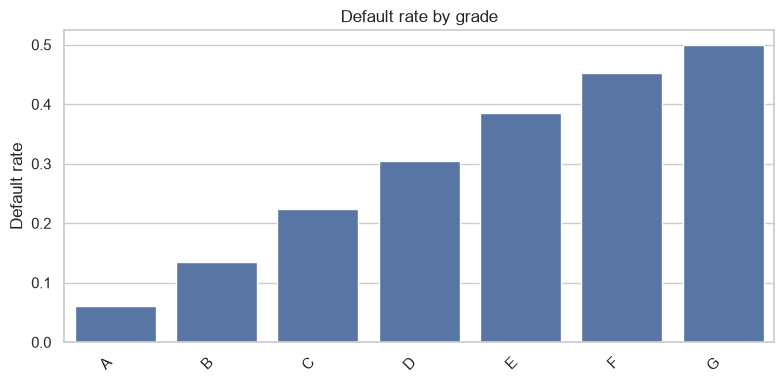

In [13]:
by_grade = default_by("grade")
display(by_grade)
plot_default(by_grade, "Default rate by grade")

שיעור הכשלים עולה באופן עקבי לפי דרגת אשראי

In [14]:
by_term = default_by("term")
display(by_term)

,segment,loans,default_rate
0,36 months,1020743,0.160
1,60 months,324567,0.324


הלוואות לטווח ארוך יותר מסוכנות יותר

,segment,loans,default_rate
0,small_business,15416,0.297
1,renewable_energy,933,0.237
2,moving,9480,0.234
3,house,7253,0.219
4,medical,15554,0.218
5,debt_consolidation,780321,0.211
6,other,77875,0.210
7,vacation,9065,0.192
8,major_purchase,29425,0.186
9,home_improvement,87504,0.177


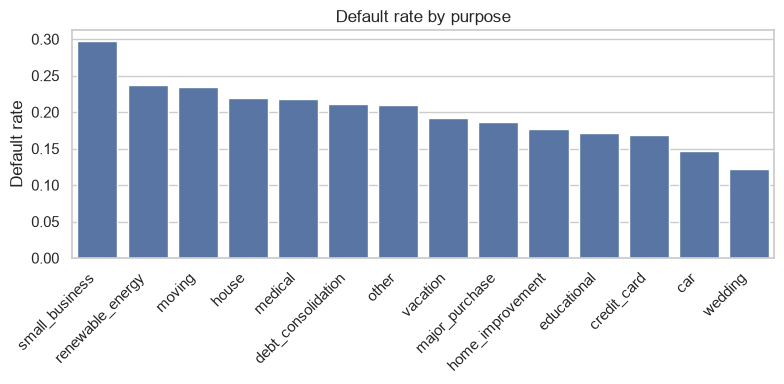

In [15]:
by_purpose = default_by("purpose", order_by="3 DESC")
display(by_purpose)
plot_default(by_purpose, "Default rate by purpose")

הלוואות לעסקים קטנים נוטות לשיעור כשלים גבוה
הלוואות לחתונות נוטות לשיעור כשלים נמוך

,segment,loans,default_rate
0,2007,251,0.179
1,2008,1562,0.158
2,2009,4716,0.126
3,2010,11536,0.129
4,2011,21721,0.152
5,2012,53367,0.162
6,2013,134804,0.156
7,2014,223102,0.184
8,2015,375545,0.202
9,2016,293095,0.233


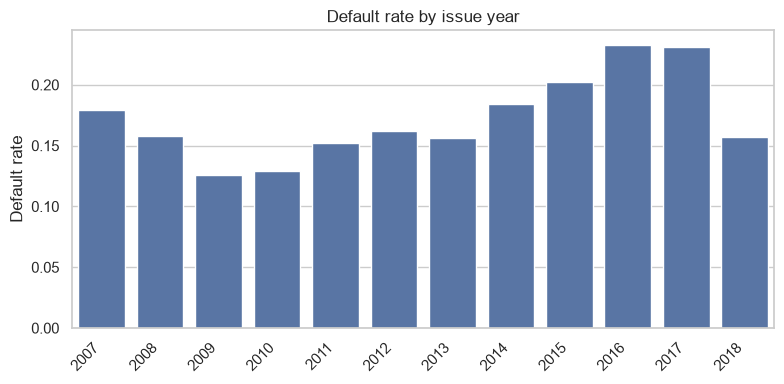

In [ ]:
by_year = default_by("issue_year")
display(by_year)
plot_default(by_year, "Default rate by issue year")

שיעור הכשל בשנת 2018 נמוך יחסית - מדובר באשליה חלקית בלבד - רק 56311 הלוואות הושלמו - כלומר, רוב ההלוואות עדיין לא הבשילו - יש להמתין 36 חודשים עד 60 חודשים על מנת לקבל את שיעור הכשלים האמיתי

Right-censoring - מושג בסטטיסטיקה
אנחנו יודעים שאירוע מסוים עדיין לא התרחש עד לנקודת זמן מסוימת
אבל אנחנו לא יודעים מתי הוא יתרחש בפועל

In [16]:
df = con.sql("SELECT * FROM loans").df()

missing = df.isna().mean().mul(100).round(1).sort_values(ascending=False)
missing[missing > 0]

emp_length              5.8
mort_acc                3.5
revol_util              0.1
pub_rec_bankruptcies    0.1
dtype: float64

שיעור הערכים החסרים בכל אחד מן הקטגוריות בטבלה
יש להחליט כיצד להשלים את הערכים החסרים הללו - מחיקה, מילוי בחציון, יצירת משתנה בוליאני חסר\קיים

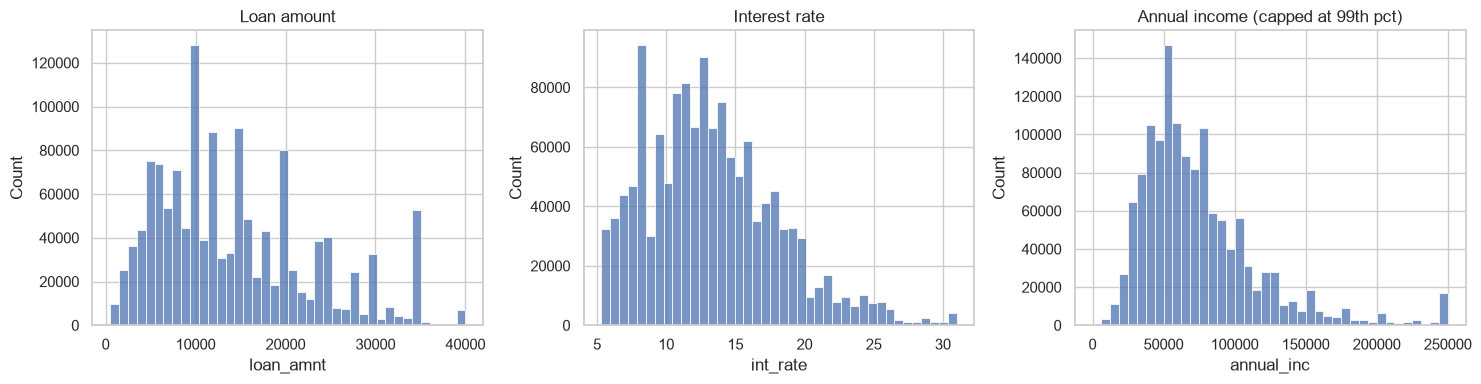

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["loan_amnt"], bins=40, ax=axes[0])
axes[0].set_title("Loan amount")

sns.histplot(df["int_rate"], bins=40, ax=axes[1])
axes[1].set_title("Interest rate")

inc = df["annual_inc"].clip(upper=df["annual_inc"].quantile(0.99))
sns.histplot(inc, bins=40, ax=axes[2])
axes[2].set_title("Annual income (capped at 99th pct)")

plt.tight_layout()
plt.show()

טבלה 1 - סכום ההלוואה
טבלה 2 - ריבית
טבלה 3 - הכנסה שנתית

In [18]:
df["dti_bucket"] = pd.cut(df["dti"], [0, 10, 20, 30, 40, 1000], right=False)
print(df.groupby("dti_bucket", observed=True)["is_default"].agg(["count", "mean"]))

df["inc_bucket"] = pd.qcut(df["annual_inc"], 5)
print(df.groupby("inc_bucket", observed=True)["is_default"].agg(["count", "mean"]))

             count      mean
dti_bucket                  
[0, 10)     245712  0.148849
[10, 20)    561904  0.178365
[20, 30)    408641  0.230430
[30, 40)    121907  0.290869
[40, 1000)    6770  0.305465
                         count      mean
inc_bucket                              
(-0.001, 42000.0]       275103  0.234770
(42000.0, 57000.0]      268342  0.215956
(57000.0, 74000.0]      265191  0.203137
(74000.0, 100000.0]     286633  0.184361
(100000.0, 10999200.0]  250041  0.157210


נשים לב שלווים שהמדד שלהם עומד בטווח בין 0 ל10 מחזיקים בשיעור הכשל הנמוך ביותר
כלומר, 14.9% בלבד מההלוואות בקבוצה הזו נכשלו
מדובר בקשר סטטיסטי - לא ניתן להסיק שמדובר בקשר סיבתי משום שקיימים משתנים נוספים המשפיעים על כך
משתנים נוספים - הכנסה גבוהה יותר, דרגת אשראי טובה יותר, יציבות תעסוקתית גבוהה יותר ועוד

נשים לב שלווים שההכנסה השנתית שלהם עומדת בטווח בין 0 ל42,000 ש"ח מחזיקים בשיעור הכשל הגבוה ביותר
כלומר, 23% מההלוואות בקבוצת זו נכשלו
מדובר בקשר סטטיסטי - לא ניתן להסיק שמדובר בקשר סיבתי משום שקיימים משתנים נוספים המשפיעים על כך
מנגנון עקיף - לווים עם הכנסה נמוכה לרוב מקבלים ריבית גבוהה יותר
איכות הנתון - ייתכנו טעויות או הגזמות המטשטשות את הההקשר

DTI - Debt-to-Income ratio - יחס החוב להכנסה
דוגמה - לווה מרוויח 10,000 ש"ח בחודש ומשלם 3,000 ש"ח בחודש על כרטיסי אשראי, הלוואות ורכב
אז המדד שלו הוא כ- 30%

In [19]:
num = df.select_dtypes("number")
corr = num.corr()["is_default"].drop("is_default").sort_values()
corr

fico_range_low         -0.130683
fico_range_high        -0.130682
mort_acc               -0.075294
annual_inc             -0.041759
revol_bal              -0.020010
total_acc              -0.011300
delinq_2yrs             0.019381
pub_rec_bankruptcies    0.025308
pub_rec                 0.026194
open_acc                0.028078
issue_year              0.051381
installment             0.051701
revol_util              0.060048
inq_last_6mths          0.065454
loan_amnt               0.065604
dti                     0.084510
int_rate                0.258792
Name: is_default, dtype: float64

הקשר של ההכנסה השנתית חלש במדד הלינארי אך חזק בפילוח לחמישיונים
ריבית גבוהה מובילה לשיעור כשלים גבוה יותר